# NB Pipeline explanatory notebooks
## Notebook 2: Negative Binomial Model

The statistical model chosen to model clonotype counts is the Negative Binomial Distribution. In this notebook we will justify the choice of this distribution as well as the corrections made to it using biological considerations that arose in the EDA phase of section 1. We validate the model using simulations.

The objectgive of the pipeline is to determine which patient clonotypes are non-neutral. This is done by testing them agains a **null model** or **null hypothesis**, which we establish using **healthy donors**. In the literature, the most common way to establish a **null model** is using technical replicates from which the sampling noise can be determined, allowing to distinghish what is biological non-neutrality. Why use donors instead of replicates?
* `Resource/Funding contrains`: Technical replicates are expensive and not always a viable option due to resource limiation, as is our case. This would put our pipeline is a graceful spot with respect to other T-cell dynamics methdologies. All RNA-seq based methods rely on technical replicates for noise estiamtion, and even though some of them give the option to perfor analysis without them, they do specificallyt adress the propblems that arise from not using them. Our pipeline does adress them.
* `Bilological considerations`: There is also a biological argument to not use technical replicates (**REFERENCE**), or rather, to use healthy donors. Tehcnical replicates come from the patients own samples, which are expected to have more uderlying non-neutrality than a healthy person. During the computation of the sample noise, part of the genuine biology happening in the clonotype trajectotries can get confounded with technical noise, obscuring the detection of neutral clonotypes. By using healthy donors as the null baseline, we are asking a fundamentally different question for the null: How do healthy T-cell dynamics look like? 

In [1]:
import sys
sys.path.insert(0, '..')

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from tcr_pipeline.normalization import tmm_normalize
from tcr_pipeline.data_io import sample_qc, drop_failed_samples
from tcr_pipeline import nb_glm as nb

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)

DONOR_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']
GREY, INK = '#8a8984', '#3d3c39'
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6,
    'axes.edgecolor': GREY, 'axes.labelcolor': INK, 'xtick.color': '#52514e',
    'ytick.color': '#52514e', 'lines.linewidth': 1.6, 'lines.markersize': 5,
    'legend.frameon': False, 'font.size': 9.5, 'axes.titlesize': 10})


In [3]:

healthy_raw = pd.read_csv('../data/healthy_raw.csv', index_col=0)
d_qc = nb.attach_offset(tmm_normalize(drop_failed_samples(healthy_raw, sample_qc(healthy_raw))))

DONORS = sorted(d_qc['patient'].unique())
COLOR = dict(zip(DONORS, DONOR_COLORS))
short = lambda p: p.replace('_SEQTR', '').replace('_ReSeq', '')
print(len(d_qc), 'rows,', d_qc.groupby(['patient', 'day']).ngroups, 'samples,',
      len(DONORS), 'donors')

2969286 rows, 23 samples, 6 donors


## 2.1 The model

For clone $c$ in sample $t$ of one person, the read count is

$$x_{ct} \sim \mathrm{NB}\!\left(\mu_{ct},\ \phi\right), \qquad
\log\mu_{ct} = \log L_t\ + \log\lambda_c + \beta_c s_t, \qquad s_t = \frac{t-\bar{t}}{t_{last} - t_{first}},\qquad
\mathrm{Var}(x_{ct}) = \mu_{ct} + \frac{\mu_{ct}^2}{\phi}.$$

* $\lambda_c$ is the clone's frequency. Under the **null** it is the same in every
  sample: the clone neither expands nor contracts.
* $L_t = D_t \times \text{TMM}_t$ is the sample's **offset**: its in-frame depth $D_t$
  (Section 1.1) times a TMM normalisation factor computed within the person, so that
  $\mu_{ct}$ is the expected count of a clone of frequency $\lambda_c$ in that sample. We use TMM as a robust normalization factor to correct for different sequencing depth across samples, but other normalization factor can be used.
* $\phi$ is the **dispersion**. The NB is a Poisson whose mean is itself multiplied by
  a random factor with mean 1 and squared coefficient of variation $1/\phi$. This dispersion (sometimes called overdispersion) encapsulates
  sample-to-sample noise of library preparation, RNA content per cell, amplification.
  Small $\phi$ means noisy, $\phi \to \infty$ is a Poisson (only pure sampling noise).
* $\beta_c$: the clone’s trajectory. $s_t$ is time rescaled to run over one unit across the series, so $\beta_c$ is the log fold change from the first sample to the last. For example,   $\beta_c = \log 10$ is a 10-fold expansion over the series and $\beta_c = -\log 10$ a 10-fold contraction

This is a GLM per clone: a log link, an offset, two coefficients ($\alpha_c$, $\beta_c$) and a dispersion fixed in advance.

**The null hypothesis** $H_0: \beta_c = 0$, but the meaning of “neutral” is set by the donors. Their $\phi$ is estimated with $\beta_c = 0$ for every clone, so any fluctuation healthy clones show, technical or biological, is absorbed into $\phi$. A patient clone is therefore called non-neutral when it changes more than clones in healthy people do, not merely when it is not constant. The healthy donors are assumed neutral, so $\phi$ is estimated under the null model, $\log\mu_{ct} = \log L_t + \alpha_c$, with only $\alpha_c$ fitted per clone. If a donor clone does change, the null model reads its change as extra noise and lowers $\phi$, the conservative direction. The full model with $\beta_c$ is only fitted when patients are tested.

In [ ]:
#From now on we use the QC filtered data, dropping HDBR06 day 21
offsets = (d_qc.groupby(['patient', 'day'])[['D_t', 'tmm_factor', 'lib']].first()
             .rename(columns={'lib': 'L_t'}))
offsets.index = offsets.index.set_levels(offsets.index.levels[0].map(short), level=0)
display(offsets.round({'D_t': 0, 'tmm_factor': 3, 'L_t': 0}))

D_t  tmm_factor         L_t
patient day                                    
HD106   0    20776057.0       0.902  18744803.0
        46   20271816.0       1.070  21697106.0
        82   13155700.0       0.941  12375364.0
        131  16998893.0       1.000  16998893.0
HD197   0    16017072.0       1.000  16017072.0
        46   15062825.0       1.068  16093399.0
        82   17667150.0       1.040  18370898.0
        131  17706840.0       1.063  18815785.0
HDBR01  0    10155538.0       1.005  10205844.0
        21   12854243.0       0.878  11289341.0
        42   21302289.0       0.904  19267560.0
        126  13816805.0       1.000  13816805.0
HDBR02  0     5380856.0       1.164   6264145.0
        48    8857000.0       1.390  12310097.0
        71    6669562.0       1.000   6669562.0
HDBR03  0    10650237.0       1.026  10929221.0
        21    4888783.0       0.775   3788241.0
        35    6397513.0       1.000   6397513.0
        66    5034447.0       0.923   4648005.0
        84    5390104.0       1.007   5430235.0
HDBR06  0    10704506.0       1.000  10704506.0
        82   11483748.0       0.921  10580781.0
        105  10809851.0       0.919   9930761.0

## 2.2 Why NB instead of Poisson?
The reason of using NB over a simpler Poisson model is the count noise is not only due to pure samplign noise, but there are other external factors that need to be taken into consideration through the dispersion $\phi$. Next, we will investigate and justify this claim using the donor data itself.

For each donor, take the clones detected in **every** sample, rescale their counts to a
common depth ($x_{ct}\,\bar L / L_t$), and compute each clone's mean and variance across
samples. A Poisson predicts variance = mean (grey dashed line).

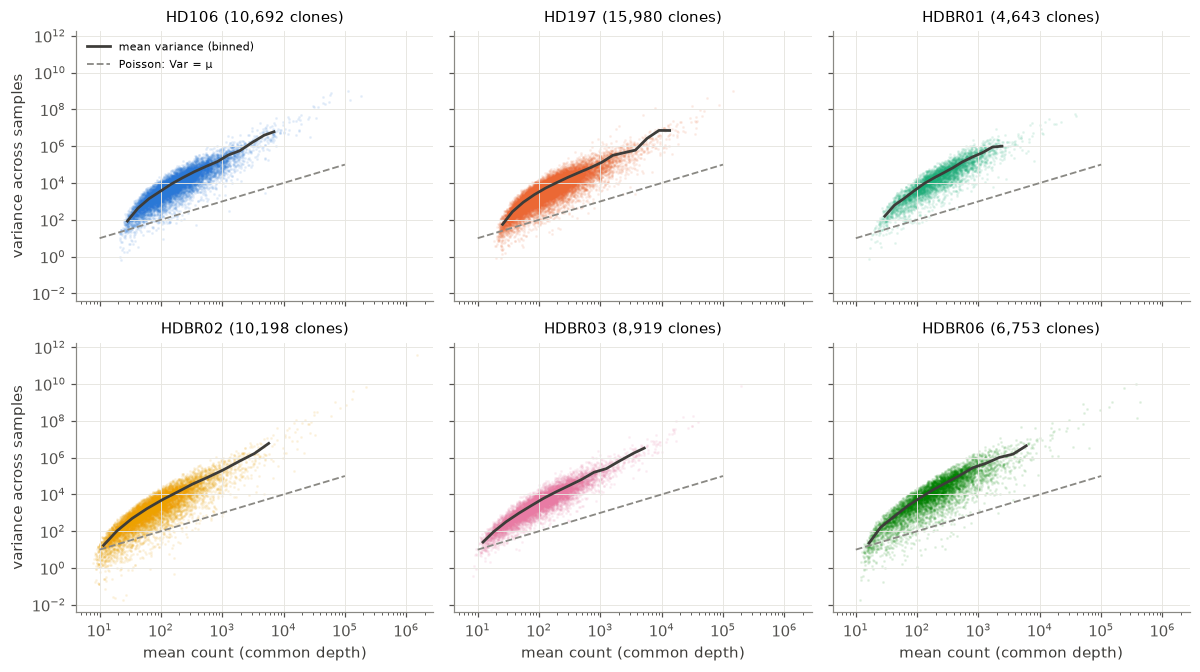

In [5]:
def mean_variance(g):
    days = np.sort(g['day'].unique())
    L = g.groupby('day')['lib'].first().reindex(days).to_numpy()
    X = (g.pivot_table(index='clono', columns='day', values='count', aggfunc='sum',
                       fill_value=0).reindex(columns=days, fill_value=0).to_numpy(float))
    Y = X[(X > 0).all(axis=1)] * (L.mean() / L)
    return Y.mean(axis=1), Y.var(axis=1, ddof=1)

fig, axes = plt.subplots(2, 3, figsize=(11, 6.2), sharex=True, sharey=True)
for ax, p in zip(axes.ravel(), DONORS):
    m, v = mean_variance(d_qc[d_qc['patient'] == p])
    edges = np.logspace(np.log10(m.min()), np.log10(m.max()), 22)
    k = np.digitize(m, edges)
    grp = [i for i in np.unique(k) if (k == i).sum() >= 20]
    mb = np.array([m[k == i].mean() for i in grp])
    vb = np.array([v[k == i].mean() for i in grp])
    ax.scatter(m, v, s=1, color=COLOR[p], alpha=0.08, rasterized=True)
    ax.plot(mb, vb, color=INK, lw=1.8, label='mean variance (binned)')
    mm = np.logspace(1, 5, 50)
    ax.plot(mm, mm, color=GREY, ls='--', lw=1.2, label='Poisson: Var = μ')
    ax.set(xscale='log', yscale='log', title=f'{short(p)} ({len(m):,} clones)')
for ax in axes[-1]:
    ax.set_xlabel('mean count (common depth)')
for ax in axes[:, 0]:
    ax.set_ylabel('variance across samples')
axes[0, 0].legend(fontsize=7.5, loc='upper left')
fig.tight_layout()

**What this shows.** The variance lies above the Poisson line for every donor, by up
to three orders of magnitude, and the gap widens with the mean. A Poisson model would
treat this ordinary sample-to-sample noise as real change and call most clones
non-neutral. 

The binned variance also grows somewhat **more slowly** at the largest
means which could hint at the fact that noise decreases with abundance.

## 2.3 Estimating $\phi$

$\phi$ is estimated per donor from the donor's own clones, with three ingredients.

* **1. Detected counts only, with a truncated likelihood.** A clone missing from a sample
is not a zero (Section 1). It may simply not have been sampled. Only detected counts
are used, and since a count is only reported when it reaches the sample's cutoff
$c_t$ (Section 1.2), each is modelled *conditional on detection*:

    $$P(x_{ct} \mid x_{ct} \ge c_t) = \frac{\mathrm{NB}(x_{ct};\ \mu_{ct}, \phi)}{P_{NB}(X \ge c_t;\ \mu_{ct}, \phi)}.$$

    Without the denominator, the counts that fell below the cutoff are silently missing
    from the low tail and the noise looks smaller than it is. 
    As a side note, in the literature, it is common to see the term *zero truncated likelihood* which corresponds to the specific case of $c_{t}=1$. This is the case when full raw count data is available without any cutoff. 

* **2. Profiling out the clone frequencies.** Every clone has its own unknown
$\lambda_c$ (thousands of nuisance parameters). For each trial value of $\phi$, every
$\lambda_c$ is set to its maximum-likelihood value (Fisher scoring), which gives the
profile likelihood $\ell_p(\phi) = \max_\lambda \ell(\phi, \lambda)$. This is, for each tested $\phi$ the values of $\lambda_c$ are computed in a inner optimization loop, where the starting value is the pooled frequency 
$$\hat{\lambda_{c}} = \frac{\sum_{t} x_{c,t}}{\sum_{t}D_{t}f_{t}}$$
    The nested optimization procedure, altough more precise is also more expensive, so a chaper version using directly the pooled $\hat{\lambda_c}$ is avaliable.

* **3. Cox–Reid adjustment.** Each clone has only 2–5 observations but its own fitted
$\hat\lambda_c$, which absorbs part of the noise and introduces bias. The adjusted profile likelihood (also known as Cox-Reid adjustment **REFERENCE**)

$$\ell_{CR}(\phi) = \ell_p(\phi) - \tfrac12 \sum_c \log I_c(\hat\lambda_c, \phi)$$

    ($I_c$: the Fisher information for $\log\lambda_c$) removes that bias.

* **4. Clones used.** Detected in at least 2 samples (a clone seen once carries no
information about variation between samples), with frequency at least 10× the
detection cutoff ($\ge 10^{-5}$) over its detected samples. **NEED TO JUSTIFY $10^{5}$**

The table compares, on the real donors, the chosen estimator with two simplified ones.

In [6]:
est = pd.DataFrame({short(p): {
    'truncated + Cox-Reid (used)': nb.fit_nb_dispersion_cr(g, min_detect=2, min_freq_mult=10, truncate=True,
                                   c_col='c_t', cox_reid=True, n_bins=1,
                                   min_bin_clones=10**9)['phi'],
    'not truncated': nb.fit_nb_dispersion_cr(g, min_detect=2, min_freq_mult=10, truncate=False,
                                    c_col='c_t', cox_reid=True, n_bins=1,
                                    min_bin_clones=10**9)['phi'],
    'no Cox-Reid': nb.fit_nb_dispersion_cr(g, min_detect=2, min_freq_mult=10, truncate=True,
                                   c_col='c_t', cox_reid=False, n_bins=1,
                                   min_bin_clones=10**9)['phi']} for p, g in d_qc.groupby('patient')}).T
display(est.round(3))

,truncated + Cox-Reid (used),not truncated,no Cox-Reid
HD106,2.350,2.472,3.370
HD197,3.651,3.684,4.975
HDBR01,1.374,1.683,2.401
HDBR02,1.804,2.035,3.079
HDBR03,1.714,1.953,2.553
HDBR06,1.328,1.609,2.438


The three estimators disagree substantially, so the choice matters. The next
subsection decides it by simulation: which one recovers a $\phi$ we know?

## 2.4 Validation of the procedure: Which methods recovers $\phi$ more accurately?
We will use simuulated data with a known $\phi$ to determine which methods more accurately recovers the true value.

min               max            
phi_true                                          1.0   1.6   3.0   1.0   1.6   3.0
scenario            estimator                                                      
5 % changing clones truncated + Cox-Reid (used)  0.72  0.82  0.82  0.83  0.89  0.89
neutral             no Cox-Reid                  1.51  1.42  1.38  1.77  1.63  1.61
                    not truncated                1.27  1.09  1.02  1.35  1.14  1.03
                    truncated + Cox-Reid (used)  0.81  0.94  0.99  0.88  0.96  1.00

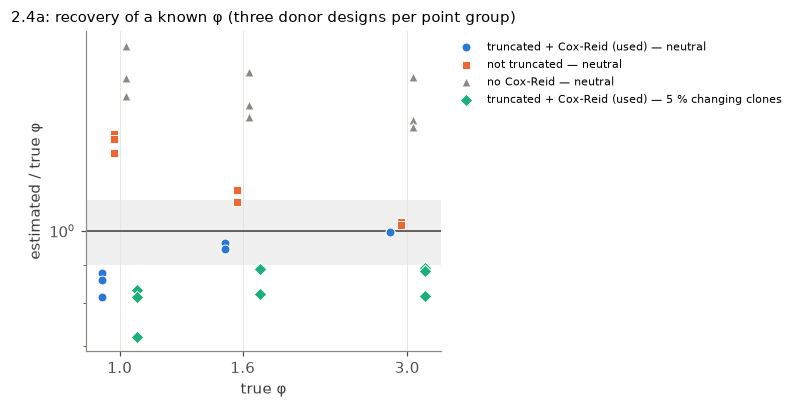

In [8]:
from tcr_pipeline import simulate

SIM_DONORS = ['HD106_SEQTR', 'HDBR03_SEQTR_ReSeq', 'HDBR06_SEQTR_ReSeq']
SIM_PHI = [1.0, 1.6, 3.0]

# %% [markdown]
# ### 2.4a Clone frequencies copied from the donor
#
# Two scenarios:
#
# * **neutral**: every clone has a constant frequency (the estimator's assumption);
# * **5 % changing clones**: 5 % of the clones follow a log-linear trend of 2–30-fold over
#   the series. The estimator assumes constant frequencies, so it can only read these
#   changes as noise; the question is in which direction, and by how much, $\phi$ moves.
#
# Three estimators are compared: the one used (truncated, Cox–Reid), the same without
# truncation, and the same without Cox–Reid.

# %%
def phi_global(g, truncate=True, cox_reid=True):
    """One phi for all clones of g: truncated, Cox-Reid, clones >= 10x the cutoff."""
    return nb.fit_nb_dispersion_cr(g, min_detect=2, min_freq_mult=10, truncate=truncate,
                                   c_col='c_t', cox_reid=cox_reid, n_bins=1,
                                   min_bin_clones=10**9)['phi']
rows = []
for p in SIM_DONORS:
    g = d_qc[d_qc['patient'] == p]
    for phi_true in SIM_PHI:
        Nt = nb.estimate_dropout_N(g, phi=phi_true)
        for scen, frac in [('neutral', 0.0), ('5 % changing clones', 0.05)]:
            sim, _ = simulate.simulate_like_patient(g, phi_true, Nt, frac_spike=frac, seed=11)
            for name, kw in [('truncated + Cox-Reid (used)', {}),
                             ('not truncated', dict(truncate=False)),
                             ('no Cox-Reid', dict(cox_reid=False))]:
                if scen != 'neutral' and name != 'truncated + Cox-Reid (used)':
                    continue
                rows.append({'donor design': short(p), 'phi_true': phi_true,
                             'scenario': scen, 'estimator': name,
                             'phi_hat': phi_global(sim, **kw)})
simres = pd.DataFrame(rows)
simres['phi_hat / phi_true'] = simres['phi_hat'] / simres['phi_true']
display(simres.pivot_table(index=['scenario', 'estimator'], columns='phi_true',
                           values='phi_hat / phi_true', aggfunc=['min', 'max']).round(2))

# %%
fig, ax = plt.subplots(figsize=(7.2, 3.8))
styles = {('neutral', 'truncated + Cox-Reid (used)'): ('#2a78d6', 'o'),
          ('neutral', 'not truncated'): ('#eb6834', 's'),
          ('neutral', 'no Cox-Reid'): ('#8a8984', '^'),
          ('5 % changing clones', 'truncated + Cox-Reid (used)'): ('#1baf7a', 'D')}
for k, ((scen, name), (col, mk)) in enumerate(styles.items()):
    s = simres[(simres['scenario'] == scen) & (simres['estimator'] == name)]
    x = np.log(s['phi_true']) + (k - 1.5) * 0.045
    ax.scatter(x, s['phi_hat / phi_true'], color=col, marker=mk, s=34, edgecolor='white',
               linewidth=0.6, zorder=3, label=f'{name} — {scen}')
ax.axhline(1, color=INK, lw=1)
ax.axhspan(0.9, 1.1, color=GREY, alpha=0.12, lw=0)
ax.set(xticks=np.log(SIM_PHI), xticklabels=[str(v) for v in SIM_PHI], xlabel='true φ',
       ylabel='estimated / true φ', yscale='log',
       title='2.4a: recovery of a known φ (three donor designs per point group)')
ax.legend(fontsize=7.5, loc='upper left', bbox_to_anchor=(1.01, 1))
fig.tight_layout()

,alpha,SE,clones above 3e-5,largest clone
HD106,2.3003,0.0339,1474.0,0.0105
HD197,2.1789,0.0270,1902.0,0.0086
HDBR01,2.8430,0.0460,1604.0,0.0026
HDBR02,2.2145,0.0273,1980.0,0.1987
HDBR03,2.3567,0.0257,2793.0,0.0303
HDBR06,2.4217,0.0272,2730.0,0.0389


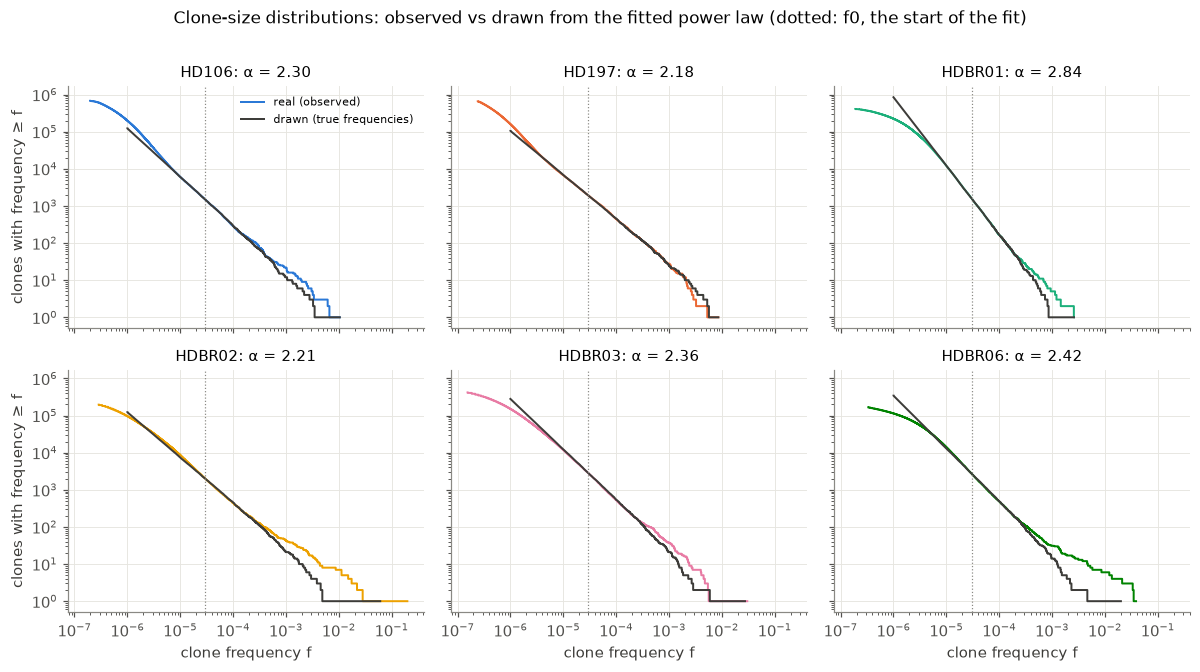

In [9]:
# %% [markdown]
# ### 2.4b Clone frequencies drawn from a power law
#
# Copying each observed clone's frequency has two weaknesses. A rare clone's frequency is
# computed over the samples where it was **detected**, so rare clones are copied with
# frequencies that are too high (they were detected *because* their counts happened to be
# high). And clones that were never observed are missing altogether. Both change which
# clones reach the estimation floor.
#
# Instead, a repertoire of *true* frequencies is drawn from the clone-size distribution.
# Above $f_0 = 3 \times 10^{-5}$ (30× the cutoff, where detection barely affects the
# frequencies) the distribution is a power law,
# $P(F > f) = (f/f_0)^{-(\alpha - 1)}$, fitted per donor by maximum likelihood (Hill
# estimator, as in Section 1.3). The same law is extended down to the cutoff ($10^{-6}$),
# with as many clones as it implies. These frequencies then go through steps 3–7 above.
 
# %%
pls = {p: simulate.fit_powerlaw(d_qc[d_qc['patient'] == p]) for p in DONORS}
display(pd.DataFrame({short(p): {'alpha': r['alpha'], 'SE': r['se'],
                                 'clones above 3e-5': r['n0'], 'largest clone': r['f_max']}
                      for p, r in pls.items()}).T.round(4))
 
fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharex=True, sharey=True)
for ax, p in zip(axes.ravel(), DONORS):
    g = d_qc[d_qc['patient'] == p]
    f_real = np.sort(simulate.pooled_frequency(g).to_numpy())[::-1]
    f_draw = np.sort(simulate.draw_powerlaw(pls[p], f_lo=1e-6, seed=1))[::-1]
    for f, col, lab in [(f_real, COLOR[p], 'real (observed)'),
                        (f_draw, INK, 'drawn (true frequencies)')]:
        ax.step(f, np.arange(1, len(f) + 1), where='post', color=col, lw=1.3, label=lab)
    ax.axvline(pls[p]['f0'], color=GREY, lw=0.8, ls=':')
    ax.set(xscale='log', yscale='log', title=f"{short(p)}: α = {pls[p]['alpha']:.2f}")
for ax in axes[-1]:
    ax.set_xlabel('clone frequency f')
for ax in axes[:, 0]:
    ax.set_ylabel('clones with frequency ≥ f')
axes[0, 0].legend(fontsize=7.5)
fig.suptitle('Clone-size distributions: observed vs drawn from the fitted power law '
             '(dotted: f0, the start of the fit)', y=1.01)
fig.tight_layout()

In [10]:
rows = []
for p in SIM_DONORS:
    g = d_qc[d_qc['patient'] == p]
    lam = simulate.draw_powerlaw(pls[p], f_lo=1e-6, seed=11)
    for phi_true in SIM_PHI:
        Nt = nb.estimate_dropout_N(g, phi=phi_true)
        for freqs, kw in [('donor, 1:1 (2.4a)', {}), ('power law (2.4b)', {'frequencies': lam})]:
            sim, _ = simulate.simulate_like_patient(g, phi_true, Nt, frac_spike=0.0, seed=11, **kw)
            rows.append({'donor design': short(p), 'phi_true': phi_true, 'frequencies': freqs,
                         'phi_hat / phi_true': phi_global(sim) / phi_true,
                         'clones used for φ': simulate.repertoire_summary(sim)['clones used for phi']})
plres = pd.DataFrame(rows)
display(plres.pivot_table(index=['donor design', 'frequencies'], columns='phi_true',
                          values='phi_hat / phi_true').round(2))
n_real = {short(p): simulate.repertoire_summary(d_qc[d_qc['patient'] == p])['clones used for phi']
          for p in SIM_DONORS}
display(plres.groupby(['donor design', 'frequencies'])['clones used for φ'].median()
             .unstack().assign(real=pd.Series(n_real)).astype(int))

phi_true                         1.0   1.6   3.0
donor design frequencies                        
HD106        donor, 1:1 (2.4a)  0.81  0.95  0.99
             power law (2.4b)   0.91  0.97  1.00
HDBR03       donor, 1:1 (2.4a)  0.88  0.96  1.00
             power law (2.4b)   0.90  0.96  1.00
HDBR06       donor, 1:1 (2.4a)  0.86  0.94  1.00
             power law (2.4b)   0.86  0.94  0.99

frequencies,"donor, 1:1 (2.4a)",power law (2.4b),real
donor design,,,
HD106,42221,6553,7966
HDBR03,59950,12376,17964
HDBR06,35377,9495,9661


,alpha (above 3e-5),alpha_low (below),N (cells per sample),phi_tech,clones in the repertoire
HD106,2.300,2.348,220524.103,6.277,3105541.786
HD197,2.179,2.242,286910.281,12.708,2150001.804
HDBR01,2.843,2.153,175301.844,2.684,1835222.420
HDBR02,2.215,2.152,161523.157,4.221,1488253.355
HDBR03,2.357,1.948,287153.877,2.714,888400.241
HDBR06,2.422,1.961,139939.313,2.487,964289.521


clones per sample (median)  distinct clones  fraction seen once  clones used for phi  median count  power-law alpha (f >= 3e-5)
HD106  real                         193853.0         678329.0               0.917               7966.0          43.0                        2.300
       simulated                    193945.0         617110.0               0.814              11309.0          79.0                        2.352
HD197  real                         186953.0         654981.0               0.899               7889.0          37.0                        2.179
       simulated                    186981.0         555546.0               0.764              10250.0          63.0                        2.205
HDBR01 real                         112484.0         408644.0               0.915              12376.0          65.0                        2.843
       simulated                    112444.0         341812.0               0.788              16487.0          75.0                        2.862
HDBR02 real                          87988.0         196932.0               0.859               8115.0          20.0                        2.215
       simulated                     87928.0         214706.0               0.822              17235.0          50.0                        2.256
HDBR03 real                         100372.0         419827.0               0.839              17964.0          20.0                        2.357
       simulated                     99838.0         299302.0               0.652              13836.0          24.0                        2.358
HDBR06 real                          65536.0         167251.0               0.882               9661.0          58.0                        2.422
       simulated                     65363.0         149993.0               0.771              15654.0          77.0                        2.427

,tested,FPR (p < 0.05),FPR (p < 0.01),BH calls (q < 0.05)
donor design,,,,
HD106,6883,0.0237,0.0038,0
HD197,8060,0.0368,0.0053,0
HDBR01,8270,0.0192,0.0021,0
HDBR02,8025,0.0177,0.0010,0
HDBR03,10067,0.0384,0.0082,0
HDBR06,8372,0.0096,0.0004,0


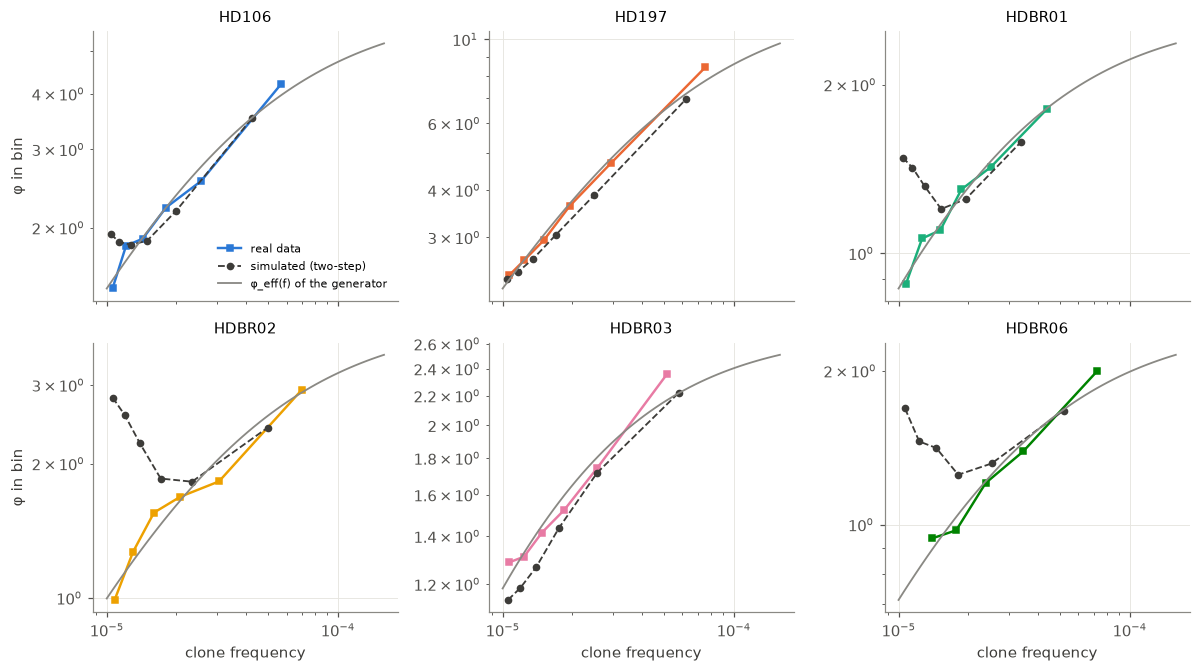

In [11]:
cal = {p: simulate.calibrate_two_step(d_qc[d_qc['patient'] == p]) for p in DONORS}
display(pd.DataFrame({short(p): {'alpha (above 3e-5)': c['pl']['alpha'],
                                 'alpha_low (below)': c['alpha_low'],
                                 'N (cells per sample)': c['N'],
                                 'phi_tech': c['phi_tech'],
                                 'clones in the repertoire': c['n_clones']}
                      for p, c in cal.items()}).T.round(3))
 
def two_step_sim(p, seed):
    c = cal[p]
    lam = simulate.draw_powerlaw(c['pl'], f_lo=c['f_lo'], alpha_low=c['alpha_low'], seed=seed)
    s, _ = simulate.simulate_two_step(d_qc[d_qc['patient'] == p], lam, c['N'], c['phi_tech'],
                                      seed=seed)
    return s
 
sims_c = {p: two_step_sim(p, seed=1) for p in DONORS}
real_vs = pd.concat({short(p): pd.DataFrame({
    'real': simulate.repertoire_summary(d_qc[d_qc['patient'] == p]),
    'simulated': simulate.repertoire_summary(sims_c[p])}).T for p in DONORS})
display(real_vs.round(3))
 
# %% [markdown]
# The number of clones per sample is matched by construction. The other statistics are
# **not** fitted and show how realistic the generator is: compare the fraction of clones
# seen only once, the size of the estimation set and the median count with the real
# values.
 
# %%
# phi(f) estimated on the simulated data, against phi_eff(f) and the real donor's bins
fig, axes = plt.subplots(2, 3, figsize=(11, 6.2), sharex=True)
ff = np.logspace(-5, -3.8, 50)
tr_sim = {}
for ax, p in zip(axes.ravel(), DONORS):
    tr_sim[p] = nb.fit_phi_trend(sims_c[p])
    sb = tr_sim[p]['bins'][~tr_sim[p]['bins']['at_bound']]
    rb = nb.fit_phi_trend(d_qc[d_qc['patient'] == p])['bins']
    rb = rb[~rb['at_bound']]
    ax.plot(10 ** rb['log10_freq'], rb['phi'], 's-', color=COLOR[p], ms=4.5, label='real data')
    ax.plot(10 ** sb['log10_freq'], sb['phi'], 'o--', color=INK, ms=4, lw=1.2,
            label='simulated (two-step)')
    ax.plot(ff, simulate.phi_eff(ff, cal[p]['N'], cal[p]['phi_tech']), color=GREY, lw=1.2,
            label='φ_eff(f) of the generator')
    ax.set(xscale='log', yscale='log', title=short(p))
for ax in axes[-1]:
    ax.set_xlabel('clone frequency')
for ax in axes[:, 0]:
    ax.set_ylabel('φ in bin')
axes[0, 0].legend(fontsize=7.5)
fig.tight_layout()
 
# %%
# end to end: phi(f) from simulation 1, test an independent neutral simulation 2
RUN_E2E = True
if RUN_E2E:
    rows = []
    for p in DONORS:
        s2 = two_step_sim(p, seed=2)
        trend = tr_sim[p]['trend']
        Nt = nb.estimate_dropout_N(s2, phi=trend)
        r = nb.nb_trajectory_test(s2, trend, likelihood='dropout', dropout_N=Nt,
                                  min_freq=1e-5, beta_bound=np.log(100))
        r = nb.add_qvalues(r, 'p_value', by='patient')
        rows.append({'donor design': short(p), 'tested': len(r),
                     'FPR (p < 0.05)': (r['p_value'] < .05).mean(),
                     'FPR (p < 0.01)': (r['p_value'] < .01).mean(),
                     'BH calls (q < 0.05)': int((r['q_value'] < .05).sum())})
    display(pd.DataFrame(rows).set_index('donor design').round(4))

In [12]:
import pickle

with open("two_step_calibration.pkl", "wb") as f:
    pickle.dump(cal, f)

In [13]:
RUN_E2E = True
if RUN_E2E:
    rows = []
    for p in DONORS:
        s2 = two_step_sim(p, seed=2)
        trend = tr_sim[p]['trend']
        Nt = nb.estimate_dropout_N(s2, phi=trend)
        r = nb.nb_trajectory_test(s2, trend, likelihood='dropout', dropout_N=Nt,
                                  min_freq=1e-5, beta_bound=np.log(100))
        r = nb.add_qvalues(r, 'p_value', by='patient')
        rows.append({'donor design': short(p), 'tested': len(r),
                     'FPR (p < 0.05)': (r['p_value'] < .05).mean(),
                     'FPR (p < 0.01)': (r['p_value'] < .01).mean(),
                     'BH calls (q < 0.05)': int((r['q_value'] < .05).sum())})
    display(pd.DataFrame(rows).set_index('donor design').round(4))

,tested,FPR (p < 0.05),FPR (p < 0.01),BH calls (q < 0.05)
donor design,,,,
HD106,6883,0.0237,0.0038,0
HD197,8060,0.0368,0.0053,0
HDBR01,8270,0.0192,0.0021,0
HDBR02,8025,0.0177,0.0010,0
HDBR03,10067,0.0384,0.0082,0
HDBR06,8372,0.0096,0.0004,0


In [14]:

from pathlib import Path
import importlib
import inspect
import json
import numpy as np
import pandas as pd
from tcr_pipeline import nb_simulation_validation as simval

# Reload the updated helper.
simval = importlib.reload(simval)

# The updated power function must use censored likelihood by default.
assert "likelihood" in inspect.signature(
    simval.run_power_experiment_nb
).parameters, "Replace nb_simulation_validation.py with the updated version."

# -------------------- Setup --------------------
assert "d_qc" in globals(), "Run the cell that creates d_qc first."

DONORS = sorted(d_qc["patient"].unique())
RUN_DONORS = [
    p for p in globals().get("SIM_DONORS", DONORS)
    if p in DONORS
]
if not RUN_DONORS:
    RUN_DONORS = DONORS

# Reuse calibration from notebook cell 15 if available.
if "cal" not in globals() or not set(DONORS).issubset(cal):
    cal = {
        p: simulate.calibrate_two_step(
            d_qc[d_qc["patient"] == p].copy()
        )
        for p in DONORS
    }

PILOT = True
n_null = 2 if PILOT else 100
n_pattern = 1 if PILOT else 10
n_power = 2 if PILOT else 50
n_clones = 10_000 if PILOT else 30_000

out_dir = Path("simulation_results_nb")
out_dir.mkdir(parents=True, exist_ok=True)

print("Donors:", RUN_DONORS)
print("Pilot mode:", PILOT)

# ============================================================
# STEP 1 — Independent null simulations and FPR calibration
# ============================================================
null_runs, null_by_miss = simval.run_repeated_null_validation(
    d_qc=d_qc,
    donors=RUN_DONORS,
    calibration=cal,
    nb_module=nb,
    simulate_module=simulate,
    n_reps=n_null,
    master_seed=20261015,
    min_freq=1e-5,
    beta_bound=np.log(100),
    progress=True,
)

overall_null, miss_null = simval.summarise_null_validation(
    null_runs, null_by_miss
)

print("STEP 1: overall false-positive calibration")
display(overall_null.round(4))

print("STEP 1: false-positive rates by number of nondetections")
display(miss_null.round(4))

if "status" in null_runs:
    display(null_runs["status"].value_counts().to_frame("n_runs"))
    display(null_runs.loc[null_runs["status"] != "ok"])

null_runs.to_csv(out_dir / "null_runs.csv", index=False)
null_by_miss.to_csv(out_dir / "null_by_miss.csv", index=False)
overall_null.to_csv(out_dir / "null_summary.csv", index=False)
miss_null.to_csv(out_dir / "null_missingness_summary.csv", index=False)

# ============================================================
# STEP 2 — Calibrate the detection-pattern simulator
# ============================================================
# In pilot mode, tune one representative donor first.
pattern_donors = (
    ["HDBR03_SEQTR_ReSeq"]
    if PILOT and "HDBR03_SEQTR_ReSeq" in RUN_DONORS
    else RUN_DONORS
)

pattern_frames = []
pattern_targets = {}

for person in pattern_donors:
    grid, target = simval.tune_two_step_detection_pattern(
        person,
        d_qc=d_qc,
        calibration=cal,
        simulate_module=simulate,
        alpha_offsets=(
            (-0.2, 0.0, 0.2)
            if PILOT
            else (-0.4, -0.2, 0.0, 0.2, 0.4)
        ),
        N_scales=(1.0,),
        phi_tech_scales=(1.0,),
        n_reps=n_pattern,
        master_seed=77031,
        progress=True,
    )
    pattern_frames.append(grid)
    pattern_targets[person] = target

pattern_results = pd.concat(pattern_frames, ignore_index=True)

print("STEP 2: best-fitting detection-pattern candidates")
display(pattern_results.groupby("person", group_keys=False).head(5).round(4))

pattern_results.to_csv(
    out_dir / "detection_pattern_grid.csv", index=False
)
with open(out_dir / "detection_pattern_targets.json", "w") as f:
    json.dump(pattern_targets, f, indent=2)

# ============================================================
# STEP 3 — Power and FDR under known NB2 alternatives
# ============================================================
# This is a direct NB2 benchmark, not yet a planted-effect
# simulation under the two-step cell-sampling generator.
power_donors = (
    ["HDBR03_SEQTR_ReSeq"]
    if PILOT and "HDBR03_SEQTR_ReSeq" in RUN_DONORS
    else RUN_DONORS
)

power_frames = []

for person in power_donors:
    result = simval.run_power_experiment_nb(
        person,
        d_qc=d_qc,
        nb_module=nb,
        simulate_module=simulate,
        n_reps=n_power,
        n_clones=n_clones,
        phi_true=2.1,
        signal_fraction=0.05,
        signal_freq_min=1e-5,
        signal_freq_max=np.inf,
        folds=(1.0, 2.0, 4.0, 10.0),
        directions=("expansion", "contraction"),
        master_seed=119003,
        min_freq=1e-5,
        beta_bound=np.log(100),
        likelihood="censored",
        progress=True,
    )
    power_frames.append(result)

power_runs = pd.concat(power_frames, ignore_index=True)
power_summary = simval.summarise_power_results(power_runs)

print("STEP 3: power and false-discovery results")
display(power_summary.round(4))

power_runs.to_csv(out_dir / "power_runs.csv", index=False)
power_summary.to_csv(out_dir / "power_summary.csv", index=False)

print("Saved outputs to:", out_dir.resolve())


Donors: ['HD106_SEQTR', 'HDBR03_SEQTR_ReSeq', 'HDBR06_SEQTR_ReSeq']
Pilot mode: True
[HD106_SEQTR] replicate 1/2
[HD106_SEQTR] replicate 2/2
[HDBR03_SEQTR_ReSeq] replicate 1/2
[HDBR03_SEQTR_ReSeq] replicate 2/2
[HDBR06_SEQTR_ReSeq] replicate 1/2
[HDBR06_SEQTR_ReSeq] replicate 2/2
STEP 1: overall false-positive calibration


,donor,n_reps,mean_fpr_p05,median_fpr_p05,fpr_p05_q025,fpr_p05_q975,mean_fpr_p01,mean_bh_calls,fraction_reps_with_bh_call
0,HD106_SEQTR,2,0.0253,0.0253,0.0243,0.0263,0.0031,0.0,0.0
1,HDBR03_SEQTR_ReSeq,2,0.0414,0.0414,0.0408,0.0419,0.0094,0.0,0.0
2,HDBR06_SEQTR_ReSeq,2,0.0070,0.0070,0.0067,0.0074,0.0002,0.0,0.0


STEP 1: false-positive rates by number of nondetections


,donor,n_miss,reps_with_bin,mean_n_tested,mean_fpr_p05,fpr_p05_q025,fpr_p05_q975,mean_fpr_p01
0,HD106_SEQTR,0,2,6102.0,0.0166,0.0161,0.0172,0.0019
1,HD106_SEQTR,1,2,908.0,0.0836,0.0795,0.0877,0.0110
2,HDBR03_SEQTR_ReSeq,0,2,9060.0,0.0244,0.0239,0.0249,0.0037
3,HDBR03_SEQTR_ReSeq,1,2,1055.0,0.1209,0.1171,0.1247,0.0256
4,HDBR03_SEQTR_ReSeq,2,2,188.0,0.4120,0.4080,0.4160,0.1917
5,HDBR06_SEQTR_ReSeq,0,2,8441.0,0.0070,0.0067,0.0074,0.0002


,n_runs
status,
ok,6


,donor,replicate,status,n_tested,fpr_p05,fpr_p01,bh_calls_q05,any_bh_call_q05,fit_phi_bins


[HDBR03_SEQTR_ReSeq] pattern candidate 1/3
[HDBR03_SEQTR_ReSeq] pattern candidate 2/3
[HDBR03_SEQTR_ReSeq] pattern candidate 3/3
STEP 2: best-fitting detection-pattern candidates


,person,alpha_low,N_scale,phi_tech_scale,n_reps,loss,target_fraction_seen_once,target_fraction_seen_twice,target_fraction_seen_3plus,target_distinct_clones,target_clones_used_for_phi,target_median_count,target_clones_per_sample_median,sim_fraction_seen_once,sim_fraction_seen_twice,sim_fraction_seen_3plus,sim_distinct_clones,sim_clones_used_for_phi,sim_median_count,sim_clones_per_sample_median
0,HDBR03_SEQTR_ReSeq,2.1483,1.0,1.0,1,5.8743,0.8394,0.0846,0.0761,419827.0,17964.0,20.0,100372.0,0.7184,0.1705,0.1111,679420.0,16947.0,22.0,201395.0
1,HDBR03_SEQTR_ReSeq,1.9483,1.0,1.0,1,11.0635,0.8394,0.0846,0.0761,419827.0,17964.0,20.0,100372.0,0.6502,0.1846,0.1652,299762.0,13662.0,24.0,100133.0
2,HDBR03_SEQTR_ReSeq,1.7483,1.0,1.0,1,24.6138,0.8394,0.0846,0.0761,419827.0,17964.0,20.0,100372.0,0.5685,0.1911,0.2404,141550.0,11611.0,26.0,54547.0


KeyError: 'at_bound'